# Explainable RL for battery management: main results

Pure-RL PPO controller for a home battery, trained on the electricity bill only, compared with a rule-based controller on four unseen weeks, then explained with LIME.

1. Data and environment
2. Training and test profit
3. Learned behaviour (cycle margin)
4. LIME on the executed action
5. Explanations under three reward designs
6. PV and load regimes

In [ ]:
import os, sys
os.environ["OMP_NUM_THREADS"] = "1"
sys.path.append(os.path.abspath(".."))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy import stats
from joblib import Parallel, delayed
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.utils import set_random_seed

from components.MicrogridEnv import GridEnv
from components.RL_helper import eval_one_episode_RL, eval_one_episode_rule_based
from components.XAI import build_reward_df, print_policy_metrics
from experiments.common import build_train_eval_configs, eval_windows, _load_full_df, _slice_to_config
from experiments.pure_rl_search import obs_norm_from, _quiet

torch.set_num_threads(1)
os.makedirs("models", exist_ok=True)

## 1. Data and environment

In [ ]:
_, _, train_df, eval_df = build_train_eval_configs()
test_series = _load_full_df().loc[eval_df.index[0]: eval_df.index[-1] + pd.Timedelta(days=1)]  # +1 day for the lookahead
train_cfg, test_cfg = _slice_to_config(train_df), _slice_to_config(test_series)
windows = eval_windows(eval_df, n_windows=4, days=7)
norm = obs_norm_from(train_df)

print("train:", train_df.index[0], "->", train_df.index[-1])
print("test: ", eval_df.index[0], "->", eval_df.index[-1])

train: 2023-04-15 04:00:00 -> 2023-08-18 03:45:00
test:  2023-08-18 04:00:00 -> 2023-09-18 09:45:00


In [ ]:
LA = (2, 4, 8, 12, 16, 24, 32, 40)   # 0.5 h ... 10 h of day-ahead prices
OBS = dict(time_features=True, price_lookahead_steps=LA, obs_norm=norm)
BILL = dict(import_coeff=1.0, export_coeff=1.0, charge_from_grid_penalty_coeff=0.0,
            discharge_to_grid_penalty_coeff=0.0, limit_action_penalty_coeff=0.05, export_pv_coeff=0.0)

In [ ]:
def weekly_profit(model, obs_kw, wrap=lambda env: env):
    out = []
    for ws, we in windows:
        env = wrap(GridEnv(test_cfg, **obs_kw))
        _quiet(eval_one_episode_RL, env, policy=model, start_date=ws, end_date=we)
        out.append(float(_quiet(print_policy_metrics, build_reward_df(env))["financial_total"]))
    return out

## 2. Training and test profit

In [ ]:
STEPS = 300_000
SEEDS = [0, 1, 2, 3, 4]
RETRAIN = False   # False: reuse the saved models in models/

In [ ]:
def fit(name, reward, seed, steps=STEPS):
    torch.set_num_threads(1)
    set_random_seed(seed)

    def make():
        env = GridEnv(train_cfg, **OBS, **reward)
        env.reset(seed=seed)
        return env

    model = PPO("MlpPolicy", DummyVecEnv([make]), seed=seed, device="cpu", verbose=0)
    model.learn(total_timesteps=steps)
    model.save(f"models/{name}_seed{seed}")

todo = [s for s in SEEDS if RETRAIN or not os.path.exists(f"models/bill_seed{s}.zip")]
_ = Parallel(n_jobs=max(len(todo), 1))(delayed(fit)("bill", BILL, s) for s in todo)

In [ ]:
rule_based = []
for ws, we in windows:
    env = GridEnv(test_cfg)
    _quiet(eval_one_episode_rule_based, env, start_date=ws, end_date=we)
    rule_based.append(float(_quiet(print_policy_metrics, build_reward_df(env))["financial_total"]))

ppo = {s: weekly_profit(PPO.load(f"models/bill_seed{s}", device="cpu"), OBS) for s in SEEDS}

per_week = pd.DataFrame({"rule-based": rule_based, "PPO (mean of seeds)": np.mean(list(ppo.values()), axis=0)},
                        index=[str(w[0].date()) for w in windows])
display(per_week.round(2))

per_seed = pd.Series({s: np.mean(v) for s, v in ppo.items()})
rb_mean = np.mean(rule_based)
t, p = stats.ttest_1samp(per_seed, rb_mean)
print(f"rule-based {rb_mean:.2f} EUR/week")
print(f"PPO        {per_seed.mean():.2f} +/- {per_seed.std():.2f} EUR/week  ({per_seed.mean() - rb_mean:+.2f}, {100 * (per_seed.mean() - rb_mean) / abs(rb_mean):.1f}%), p = {p:.4f}")

,rule-based,PPO (mean of seeds)
2023-08-18,-58.27,-49.65
2023-08-26,-64.34,-43.67
2023-09-03,-46.81,-37.63
2023-09-11,-6.59,0.24


rule-based -44.00 EUR/week
PPO        -32.68 +/- 2.63 EUR/week  (+11.33, 25.7%), p = 0.0007


## 3. Learned behaviour

In [ ]:
ETA = 0.95 * 0.95   # round-trip efficiency
ws, we = windows[0]
model = PPO.load("models/bill_seed0", device="cpu")

def rollout(model, obs_kw=OBS):
    env = GridEnv(test_cfg, **obs_kw)
    obs = _quiet(eval_one_episode_RL, env, policy=model, start_date=ws, end_date=we)
    X = np.stack(obs["obs"].apply(lambda x: np.asarray(x, dtype=np.float32)))
    log = build_reward_df(env)
    log["time"] = pd.date_range(ws, periods=len(log), freq="15min")
    return X, log

X, rl_log = rollout(model)

env = GridEnv(test_cfg)
_quiet(eval_one_episode_rule_based, env, start_date=ws, end_date=we)
rb_log = build_reward_df(env)
rb_log["time"] = pd.date_range(ws, periods=len(rb_log), freq="15min")

def cycle(log):
    b, price = log["battery_applied_raw"].to_numpy(), log["price"].to_numpy()
    ch, dis = np.clip(b, 0, None), np.clip(-b, 0, None)
    p_ch, p_dis = (ch * price).sum() / ch.sum(), (dis * price).sum() / dis.sum()
    return p_ch, p_dis, ETA * p_dis - p_ch

print(pd.DataFrame({"RL": cycle(rl_log), "rule-based": cycle(rb_log)},
                   index=["charge price", "discharge price", "cycle margin"]).round(2))

                   RL  rule-based
charge price     0.10        0.41
discharge price  0.37        0.43
cycle margin     0.23       -0.02


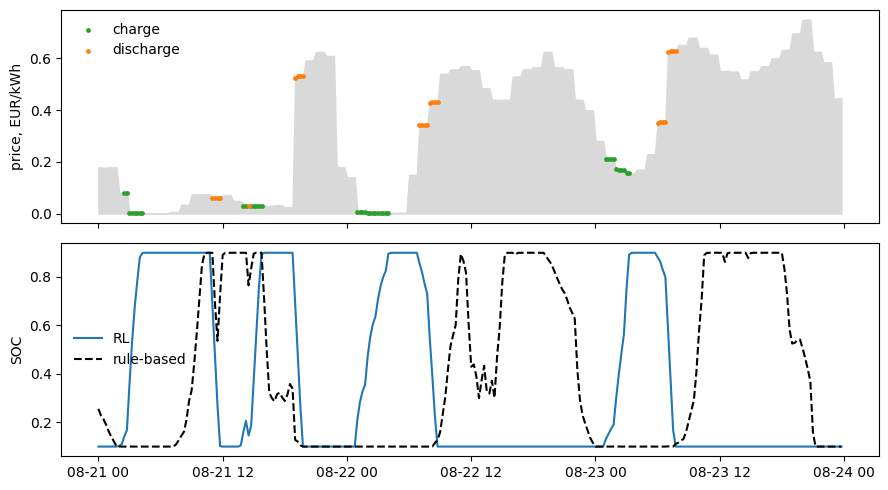

In [ ]:
day = slice("2023-08-21", "2023-08-23")
fig, ax = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
r = rl_log.set_index("time").loc[day]
ax[0].fill_between(r.index, r["price"], color="0.85")
ax[0].scatter(r.index[r["battery_applied_raw"] > 0.1], r["price"][r["battery_applied_raw"] > 0.1], s=6, c="tab:green", label="charge")
ax[0].scatter(r.index[r["battery_applied_raw"] < -0.1], r["price"][r["battery_applied_raw"] < -0.1], s=6, c="tab:orange", label="discharge")
ax[0].set_ylabel("price, EUR/kWh"); ax[0].legend(frameon=False)
ax[1].plot(r.index, r["soc"], label="RL")
ax[1].plot(rb_log.set_index("time").loc[day].index, rb_log.set_index("time").loc[day]["soc"], "--", c="k", label="rule-based")
ax[1].set_ylabel("SOC"); ax[1].legend(frameon=False)
plt.tight_layout()

## 4. LIME on the executed action

The policy output is clipped by the battery limits, so the explained quantity is the mode (discharge / idle / charge) of the executed action.

In [ ]:
from lime.lime_tabular import LimeTabularExplainer
from components.XAI import raw_to_executed_action, action_to_mode_proba

NAMES = (["SOC", "Load", "PV", "Import price", "Export price"]
         + [f"Price +{h:g}h" for h in (0.5, 1, 2, 3, 4, 6, 8, 10)] + ["sin(hour)", "cos(hour)"])
GROUPS = {"Price lookahead": NAMES[5:13], "Current price": NAMES[3:5], "SOC": ["SOC"],
          "PV": ["PV"], "Load": ["Load"], "Time of day": NAMES[13:]}

bat = GridEnv(test_cfg).microgrid.battery
BP = dict(battery_capacity=bat.capacity, high_capacity=bat.high_capacity,
          low_capacity=bat.low_capacity, max_output=bat.max_output)
soc_mean, soc_std = float(norm[0][0]), float(norm[1][0])

def lime_weights(path, X, rows):
    torch.set_num_threads(1)
    model = PPO.load(path, device="cpu")

    def predict(Z):
        Z = np.asarray(Z, dtype=np.float32)
        raw = np.asarray(model.predict(Z, deterministic=True)[0]).reshape(len(Z), -1)[:, 0]
        return np.array([action_to_mode_proba(raw_to_executed_action(float(a), soc=z[0] * soc_std + soc_mean, **BP))
                         for a, z in zip(raw, Z)], dtype=np.float32)

    explainer = LimeTabularExplainer(X, feature_names=NAMES, class_names=["discharge", "idle", "charge"],
                                     mode="classification", random_state=int(rows[0]))
    out = []
    for i in rows:
        exp = explainer.explain_instance(X[i], predict, num_features=len(NAMES), labels=(0, 1, 2))
        top = int(np.argmax(predict(X[i:i + 1])[0]))
        w = dict(exp.as_map()[top])
        out.append([w.get(j, 0.0) for j in range(len(NAMES))])
    return out

def lime_shares(path, X):
    chunks = [list(range(s, min(s + 24, len(X)))) for s in range(0, len(X), 24)]
    W = np.vstack(Parallel(n_jobs=-1)(delayed(lime_weights)(path, X, c) for c in chunks))
    absw = pd.DataFrame(np.abs(W), columns=NAMES)
    g = pd.Series({k: absw[v].sum(axis=1).mean() for k, v in GROUPS.items()})
    return 100 * g / g.sum()

shares_bill = lime_shares("models/bill_seed0", X)
print(shares_bill.round(1))
print(f"price inputs in total: {shares_bill['Price lookahead'] + shares_bill['Current price']:.1f}%")

Price lookahead    57.0
Current price      28.1
SOC                 5.9
PV                  3.0
Load                2.7
Time of day         3.2
dtype: float64
price inputs in total: 85.1%


## 5. Explanations under three reward designs

Same observations and algorithm, different reward weights: the bill only (A), the bill plus a penalty on charging from the grid (B), and the original self-consumption weights (C).

In [ ]:
CASES = {"A: bill": BILL,
         "B: + grid-charging penalty": {**BILL, "charge_from_grid_penalty_coeff": 0.5},
         "C: self-consumption weights": {}}

extra = [(n, k) for n, k in (("gridpen", "B: + grid-charging penalty"), ("selfcons", "C: self-consumption weights"))
         if RETRAIN or not os.path.exists(f"models/{n}_seed0.zip")]
_ = Parallel(n_jobs=max(len(extra), 1))(delayed(fit)(n, CASES[k], 0) for n, k in extra)
paths = {"A: bill": "models/bill_seed0", "B: + grid-charging penalty": "models/gridpen_seed0", "C: self-consumption weights": "models/selfcons_seed0"}

table, profit = {}, {}
for k, path in paths.items():
    m = PPO.load(path, device="cpu")
    profit[k] = np.mean(weekly_profit(m, OBS))
    table[k] = lime_shares(path, rollout(m)[0])

res = pd.DataFrame(table)
res.loc["price inputs, total"] = res.loc[["Price lookahead", "Current price"]].sum()
res.loc["SOC + PV + load, total"] = res.loc[["SOC", "PV", "Load"]].sum()
res.loc["test profit, EUR/week"] = pd.Series(profit)
res.round(1)

,A: bill,B: + grid-charging penalty,C: self-consumption weights
Price lookahead,57.0,50.2,36.2
Current price,28.1,12.1,3.9
SOC,5.9,17.6,28.8
PV,3.0,9.6,11.4
Load,2.7,7.0,14.3
Time of day,3.2,3.6,5.4
"price inputs, total",85.1,62.3,40.1
"SOC + PV + load, total",11.7,34.1,54.5
"test profit, EUR/week",-36.5,-45.8,-44.7


## 6. PV and load regimes

In [ ]:
act = rl_log["battery_applied_raw"] / 2
rl_log["mode"] = np.select([act > 0.05, act < -0.05], ["charge", "discharge"], "idle")

def regime_table(col, edges, labels):
    reg = pd.cut(rl_log[col], [-np.inf, *edges, np.inf], labels=labels)
    share = pd.crosstab(reg, rl_log["mode"], normalize="index").mul(100)
    share["mean SOC"] = rl_log.groupby(reg, observed=True)["soc"].mean()
    return share.round(2)

display(regime_table("pv_kwh", [0.29, 1.36], ["low", "mid", "high"]))
display(regime_table("load_kwh", [0.27, 1.09, 2.51], ["low", "med-low", "med-high", "very high"]))

mode,charge,discharge,idle,mean SOC
pv_kwh,,,,
low,20.16,11.63,68.22,0.35
mid,7.45,11.80,80.75,0.28
high,8.00,3.20,88.80,0.19


mode,charge,discharge,idle,mean SOC
load_kwh,,,,
low,18.18,11.91,69.91,0.34
med-low,6.88,8.12,85.00,0.27
med-high,18.01,6.83,75.16,0.30
very high,6.06,18.18,75.76,0.17
